# Stage 3: Multivariate analysis (several variables at once)

**Status (2026-11-03): under way**, begun on the owner's word (A32), starting with the methods the final review of
Stages 1 and 2 listed (A29) and including the check of firms' IP counts by name (A30, ADR 0045). The method is ADR
0046. The evidence atlas (the website) is frozen while Stage 3 runs (A32): nothing here changes it, and notebooks 1
and 2 stay as reviewed. Where Stage 3 changes the reading of an earlier observation, its M observation says so, and
the change waits in the handover's list for the atlas.

**Purpose.** Stage 2 found pairs of variables that move together and named, for each, the other factors that might
explain it (its *third factors*). Stage 3 looks at several variables at once to ask two things: **does each signal
survive when its third factors are held together**, and **what structure is there**: which characteristics of places,
countries, industries and institutions carry much the same information, and whether there are distinct kinds of them.
It ends with the two tables the plan asks for: early signals worth investigating, and gaps in the data.

**What it cannot do.** Holding measured factors fixed is not an experiment: factors the data does not hold can still
explain an association, and some associations may run backwards. Every finding here is observational or descriptive.
Effects need the designs that follow the EDA (natural experiments, for example), which Stage 3 can point to but not
supply.

## How to read this notebook

- **Every observation is evidenced.** Observations are numbered (**M1**, **M2**, ...) and quote the numbers from the
  output cells directly above them. If a number is not on the page, it is not a finding.
- **Each observation is labelled with its strength of evidence**, as the research goal requires: *descriptive* (what
  the data shows), *observational* (an association that may have other explanations), *causal* (an effect, which needs
  a design this EDA does not have) or *projected* (an estimate of the future). Everything in Stage 3 is descriptive or
  observational.
- **Plain English first.** Technical terms are explained where they first appear and in
  [`GLOSSARY.md`](../../GLOSSARY.md). Every chart names its source underneath it.
- **Raw, then held together.** Each signal is shown twice: as Stage 2 measured it (the **raw** figure), and with its
  third factors **held together** in one model (the **adjusted** figure). The difference between them is how much of
  the signal those factors account for. Four words describe what is left (ADR 0046):
  - **holds**: same direction, its 95% interval clear of zero, and at least half of the raw size left;
  - **weakened**: same direction and clear of zero, but less than half left;
  - **not detected once held**: the interval includes zero (which is not the same as no association);
  - **reversed**: the other direction, clear of zero;
  - and where the raw association was not detected (its interval includes zero): **appears once held** if the
    adjusted one is clear of zero, **not detected either way** if not.
- **Figures come in pairs**, as in Stage 2: a result is found in one sample and checked in a second. For rights the
  samples are two decades (FY2010 to FY2019, then FY2000 to FY2009), except where a measure is reliable only from
  FY2010 (family reach and citations, B55), when they are the two halves of FY2010 to FY2019; for firms and places,
  the lens's two halves (a fixed random split by a hash of the key); for countries, divisions and institutions, two
  periods of the same units, which is a **stability check**, not a replication. Unless an observation labels them, a
  pair is the first sample, then the second. A range in brackets with "interval" is a 95% interval.
- **Intervals** come from the model, with **clustered** standard errors where one filer has many rows (a filer's
  rights are not independent of each other), or from 1,000 resamples of the independent unit (the final review's
  request, A29). Quarterly series are resampled in blocks of consecutive quarters.
- **Unit of analysis.** Each section works on one *lens*, a table with one row per thing being described, defined in
  [`analysis/eda/build.py`](../eda/build.py) and described column by column in
  [`analysis/eda/variables.yaml`](../eda/variables.yaml). Stage 1's rules for using each column
  (`docs/stage-1-summary.md`, section 6) and Stage 2's wording rules (ADR 0043) apply here.

## 0. How Stage 3 works

**The signals carried from Stage 2** (notebook 2, section 8), where each is taken up, and the third factors named for
it:

| Stage 2 signal | Section | Third factors held together |
|---|---|---|
| B6, B10: filing alone and outcomes | 1.1, 1.2 | the filer's type, the route of filing, the technology field or class, the year, the state, joint filing, the number of classes |
| B8, B11, B12, B55: reach, citations and the share in force, by origin | 1.3 | family reach, the technology field, the route, the cohort, joint filing |
| B13: expedited examination and the share in force | 1.4 | the filer, the field, the route, the cohort |
| B16, B19: inventions filed, or now held, from overseas | 1.5 | reach, grant, the filer's type, the field, the period |
| B17, B18: women among inventors | 1.6 | the field, the filer, the year |
| B22 to B24, B50, B51: who files among firms | 2 | company form, age, place, R&D, size and industry (for employers of 100 or more) |
| B27 to B31, B58, B59: where filing happens | 3 | advantage, education, income, remoteness and business density, reduced to components first |
| B32 to B35: countries | 4 | R&D, income and size, as components |
| B37, B38, B47, B49: changes over time | 5 | trend and season |
| B40, B53, B54: industries | 6 | businesses, business R&D and the crosswalk |
| B44 to B46, B62: institutions | 7 | size, kind, research output and research spend |

**The methods the final review listed (A29)**, and where each is used: block resampling and effective sample sizes
for quarterly changes (5); 1,000 or more resamples for every quoted bootstrap interval (throughout); B42 and B60
through the crosswalk with services (6); fixed-age windows for citations (1.3 and 7, from citations within five years
of priority); research spend as an exposure for B62 (7); the window-free within-firm order for B25 (2); the
party-aligned filer for B30 (3) and, in this notebook, for clustering (1); legends on every correlation map
(throughout); and models that hold the named third factors together (throughout).

**The models.** A yes or no outcome for each right or firm (granted, still in force, a filing linked) is modelled by
logistic regression and reported as an **average marginal effect**: the difference, in percentage points, between the
predicted chance of the outcome with the signal and without it, averaged over the rows with their other factors as
they are. A count with an exposure (filing per resident) is modelled as a **negative binomial**, as in B29, and
reported as a rate ratio. The small lenses use **partial rank correlations**: the correlation of two variables'
ranks once what the third factors explain is removed from both. Where many characteristics repeat each other (places,
countries), **principal components** summarise them first, and the components are held fixed instead of the
twenty measures behind them.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import bivariate as bi
from eda import multivariate as multi
from eda import sql, style

style.setup()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
# the columns shown for every adjusted effect (multi.adjusted_effect)
EFFECT = ["rows", "share with signal", "share without", "raw", "raw low", "raw high", "adjusted", "adjusted low",
          "adjusted high", "share of raw remaining", "rows merged", "verdict"]  # fmt: skip

## 1. Lens: IP rights (one row per right)

Stage 2's shorthands carry over: **who filed** is the origin and type of one party, the first founding applicant in
Australia, else the first with a known country (`filer_group`, ADR 0037), and the **two decades** are FY2010 to FY2019
and FY2000 to FY2009. Stage 3 adds that party's **id** (from IP RAPID's parties, by the same rule), so that a filer's
rights can be treated as one cluster: a firm that files thousands of applications is one filer, not thousands of
independent cases. This is the "party-aligned filer" the final review asked for.

In [2]:
FILER = "replace(replace(filer_group, 'australian_', 'Australian '), 'overseas_', 'overseas ') || 's'"
PERIOD = (
    "CASE WHEN filing_fy BETWEEN 2010 AND 2019 THEN 'FY2010-FY2019'"
    " WHEN filing_fy BETWEEN 2000 AND 2009 THEN 'FY2000-FY2009' END"
)
# the filer's party id, by filer_group's rule (build.rights_sql): each founding applicant or owner as first recorded,
# then the first in Australia by (date, party id), else the first with a known country
FILER_PARTY = """filer_party AS (
    SELECT ip_right_type, application_number,
           coalesce(arg_min_null(party_id, (since, party_id)) FILTER (country_code = 'au'),
                    arg_min_null(party_id, (since, party_id)) FILTER (country_code IS NOT NULL)) AS filer_party,
           coalesce(arg_min_null(party_type, (since, party_id)) FILTER (country_code = 'au'),
                    arg_min_null(party_type, (since, party_id)) FILTER (country_code IS NOT NULL)) AS party_type
    FROM (
        SELECT ip_right_type, application_number, party_id, party_type, country_code, effective_from_date AS since,
               row_number() OVER (PARTITION BY ip_right_type, application_number, party_id
                                  ORDER BY effective_from_date, country_code NULLS LAST, post_code NULLS LAST,
                                           state_code NULLS LAST) AS k
        FROM {iprapid/party}
        WHERE party_role_category IN ('applicant', 'owner') AND is_founding
    ) WHERE k = 1
    GROUP BY ALL
)"""


def rsql(q, **kw):
    # sql() with the shorthands @FILER (who filed), @PERIOD (the two decades) and @FILER_PARTY (the filer's party)
    return sql(q.replace("@FILER_PARTY", FILER_PARTY).replace("@FILER", FILER).replace("@PERIOD", PERIOD), **kw)


REACH = (
    "CASE WHEN family_offices = 1 THEN 'Australia only' WHEN family_offices BETWEEN 2 AND 4 THEN 'two to four offices'"
    " WHEN family_offices >= 5 THEN 'five or more offices' ELSE 'reach unknown' END"
)
DOP_FY = "(year(date_of_patent) + (month(date_of_patent) >= 7)::INT)"
ORG_COLUMNS = f"""
    (filer_group = 'australian_organisation')::INT AS australian, {REACH} AS reach,
    coalesce(main_area, 'unknown') AS field, coalesce(filing_route, 'unknown') AS route,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    CASE WHEN class_count IS NULL THEN 'unknown' WHEN class_count = 1 THEN '1' WHEN class_count <= 3 THEN '2-3'
         ELSE '4+' END AS classes,
    coalesce(filer_party, application_number) AS filer_party"""
ORGS = "patent_type = 'standard' AND filer_group IN ('australian_organisation', 'overseas_organisation')"
HALF = bi.half_sql("application_number")


def org_rows(select, where):
    return rsql(f"""
        WITH @FILER_PARTY
        SELECT {ORG_COLUMNS}, {select}
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE {ORGS} AND {where}
        ORDER BY hash(application_number || 'stage3'), application_number
        LIMIT 200000
    """)


# Patents' lifetimes (1.3, 1.4), as Stage 2's curves read them (ADR 0041): granted standard patents, each joining the
# count at its grant (delayed entry), years from the date of patent, followed to 10 years
LIFE = "years_in_force >= 0 AND in_force IS NOT NULL AND (in_force OR retired_date >= registered_date)"
LIFETIME = (
    "years_in_force AS t, (NOT in_force)::INT AS ended,"
    " greatest(date_diff('day', date_of_patent, registered_date) / 365.25, 0) AS entry"
)


# check: the party found by the rule has the type filer_group gives, for every right with a filer
check = rsql("""
    WITH @FILER_PARTY
    SELECT count(*) AS rights_with_a_filer, count(filer_party) AS with_a_party,
           avg((split_part(filer_group, '_', 2) = party_type)::INT) AS type_agrees
    FROM {lens/rights} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
    WHERE filer_group IS NOT NULL
""")
check

,rights_with_a_filer,with_a_party,type_agrees
0,3769615,3769615,1


### 1.1 Filing alone and what comes of it, with the filer's other characteristics held together

**Revisits:** B6. **Informs:** Q2, Q4. Stage 2 found that Australian individuals' standard patents filed without an
attorney are granted about 36 points less often, in both decades and among examined applications too, and that
Australians' trade marks with an attorney are registered about 24 points more often. Its candidate third factors were
the route of filing and the filer's other characteristics. Here each gap is modelled with them held together.

**What is held fixed, and what is not.** Only what is settled when the application is filed: the **route** (PCT,
convention priority, an Australian priority, divisional, direct), the **filing year**, the founding applicant's
**state** and whether there are **several founding applicants**; for trade marks also the **Nice class** and the
**number of classes**, which the applicant chooses at filing. For patents, the technology field and the number of IPC
classes are not settled at filing: they are assigned as the application is classified, and an application abandoned
early may never be (37% of individuals' lone standard patents have no field, against none with an attorney). Holding
them fixed would hold part of the outcome fixed, so they are a **second reading** among applications that have a
field (the rows marked "with a field", which hold the field and the number of classes too). Whether **examination was requested** is a third reading, as in B6: it follows the choice to file alone.

Decided years only (filed FY2000 to FY2019), filed alone or with an attorney (agents who are not attorneys left out, as
in B6); standard errors clustered by the filer's party. Trade marks are capped at 200,000 rights in each group and
decade, chosen by a hash of the application number, as Stage 2's screens were.

In [3]:
REP_COLUMNS = """
    (registered_date IS NOT NULL)::INT AS granted, (representation = 'self')::INT AS alone,
    (exam_requested_date IS NOT NULL)::INT AS examined,
    coalesce(filing_route, 'unknown') AS route,
    coalesce(CASE WHEN ip_right_type = 'patent' THEN main_area ELSE main_class END, 'unknown') AS field,
    filing_fy, coalesce(founder_state, 'unknown') AS state,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    CASE WHEN class_count IS NULL THEN 'unknown' WHEN class_count = 1 THEN '1' WHEN class_count <= 3 THEN '2-3'
         ELSE '4+' END AS classes,
    coalesce(filer_party, application_number) AS filer_party"""
AT_FILING = ["route", "filing_fy", "state", "founders"]
TYPES = {
    "standard": "Standard patents (granted)",
    "trade_mark": "Trade marks (registered)",
}
WHO = {
    "australian_individual": "Australian individuals",
    "australian_organisation": "Australian organisations",
}
rows, sizes = [], []
for t, tname in TYPES.items():
    for fg, who in WHO.items():
        for lo, hi in ((2010, 2019), (2000, 2009)):
            d = rsql(f"""
                WITH @FILER_PARTY
                SELECT {REP_COLUMNS}
                FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
                WHERE coalesce(patent_type, ip_right_type) = '{t}' AND filer_group = '{fg}'
                  AND filing_fy BETWEEN {lo} AND {hi} AND representation IN ('self', 'attorney')
                ORDER BY hash(application_number || 'stage3'), application_number
                LIMIT 200000
            """)
            name = f"{tname}: {who}, FY{lo}-FY{hi}"
            lone = d.loc[d.alone == 1, "filer_party"].value_counts()
            sizes.append(
                {
                    "rights": name,
                    "rows": len(d),
                    "filers": d.filer_party.nunique(),
                    "filed alone": d.alone.sum(),
                    "filers filing alone": len(lone),
                    "top 10 lone filers' share": lone.head(10).sum() / lone.sum(),
                }
            )
            if t == "trade_mark":
                readings = {"": (d, AT_FILING + ["field", "classes"])}
            else:
                readings = {
                    "": (d, AT_FILING),
                    ", with a field": (
                        d[d.field != "unknown"],
                        AT_FILING + ["field", "classes"],
                    ),
                    ", examined": (d[d.examined == 1], AT_FILING),
                }
            for suffix, (sub, controls) in readings.items():
                r = multi.adjusted_effect(sub, "granted", "alone", controls, cluster="filer_party")
                rows.append(r.rename(name + suffix))
rep = pd.DataFrame(rows)
display(pd.DataFrame(sizes).set_index("rights").round(3))
rep[EFFECT].round(3)

,rows,filers,filed alone,filers filing alone,top 10 lone filers' share
rights,,,,,
"Standard patents (granted): Australian individuals, FY2010-FY2019",6041,4995,1642,1370,0.072
"Standard patents (granted): Australian individuals, FY2000-FY2009",7024,5975,1590,1374,0.034
"Standard patents (granted): Australian organisations, FY2010-FY2019",19290,7533,685,543,0.101
"Standard patents (granted): Australian organisations, FY2000-FY2009",16266,6619,1149,392,0.598
"Trade marks (registered): Australian individuals, FY2010-FY2019",101050,67608,76640,52821,0.008
"Trade marks (registered): Australian individuals, FY2000-FY2009",67102,46248,53201,38104,0.011
"Trade marks (registered): Australian organisations, FY2010-FY2019",200000,88426,86046,47674,0.028
"Trade marks (registered): Australian organisations, FY2000-FY2009",200000,74932,92879,47015,0.028


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"Standard patents (granted): Australian individuals, FY2010-FY2019",6041,0.048,0.406,-0.358,-0.378,-0.338,-0.312,-0.34,-0.284,0.872,21,holds
"Standard patents (granted): Australian individuals, FY2010-FY2019, with a field",5426,0.077,0.406,-0.329,-0.354,-0.305,-0.272,-0.305,-0.239,0.828,193,holds
"Standard patents (granted): Australian individuals, FY2010-FY2019, examined",3751,0.191,0.535,-0.344,-0.39,-0.299,-0.305,-0.359,-0.251,0.886,9,holds
"Standard patents (granted): Australian individuals, FY2000-FY2009",7024,0.083,0.451,-0.368,-0.389,-0.348,-0.317,-0.345,-0.29,0.862,0,holds
"Standard patents (granted): Australian individuals, FY2000-FY2009, with a field",6593,0.114,0.451,-0.338,-0.362,-0.313,-0.278,-0.31,-0.247,0.824,140,holds
"Standard patents (granted): Australian individuals, FY2000-FY2009, examined",4630,0.256,0.596,-0.339,-0.382,-0.296,-0.291,-0.34,-0.242,0.858,21,holds
"Standard patents (granted): Australian organisations, FY2010-FY2019",19290,0.098,0.498,-0.4,-0.456,-0.344,-0.353,-0.406,-0.3,0.883,0,holds
"Standard patents (granted): Australian organisations, FY2010-FY2019, with a field",19013,0.164,0.498,-0.333,-0.403,-0.264,-0.279,-0.338,-0.219,0.836,22,holds
"Standard patents (granted): Australian organisations, FY2010-FY2019, examined",16249,0.324,0.577,-0.253,-0.357,-0.149,-0.232,-0.311,-0.154,0.919,19,holds
"Standard patents (granted): Australian organisations, FY2000-FY2009",16266,0.621,0.56,0.06,-0.302,0.423,0.06,-0.185,0.306,1.005,18,not detected either way


### 1.2 No agent before the first renewal, and the share in force after it, with other factors held together

**Revisits:** B10. **Informs:** Q2, Q4. Stage 2 found that Australians' trade marks with no agent before the first
renewal are less often in force after it (31.7% against 50.8% with an attorney), and designs likewise at their one
renewal. The definitions are B10's (ADR 0041): a right is counted if it was registered, its cohort is the financial
year its term began (its earliest filing date), "no agent before the renewal" means filed alone or with an agent first
recorded after the renewal fell due (9.5 years after filing for trade marks, 4.5 for designs), and it is compared with
an attorney recorded before the renewal (other agents left out). "In force after 10 years" (trade marks) or "after 5
years" (designs) is a yes or no for each right, with its end rounded to a tenth of a year as Stage 2's curves were;
every cohort here has had the full time, so no right is cut short.

**Held together:** the filer's **type** (individual or organisation), the **class** (Nice for trade marks, Locarno for
designs), the **number of classes**, the **state**, **several founding applicants**, the **route** and the **cohort
year**, all settled at filing. Trade marks: cohorts FY2010 to FY2015, then FY2003 to FY2009, as in B10. Designs: B5
found that design agents were recorded differently before FY2010, so designs are read in FY2010 to FY2019 only, with
the two halves of those designs as the second sample. Capped at 200,000 rights a sample by the hash, clustered by the
filer's party.

In [4]:
TERM_FY = "(year(earliest_filed_date) + (month(earliest_filed_date) >= 7)::INT)"


def renewal_rows(t, years, cut, where):
    # B10's reading: registered rights of Australian filers, in force after `years` (the first renewal), against
    # whether an agent was recorded before the renewal fell due (`cut` years after filing)
    late = f"date_diff('day', earliest_filed_date, agent_first_date) / 365.25 > {cut}"
    return rsql(f"""
        WITH @FILER_PARTY
        SELECT (round(years_in_force, 1) > {years})::INT AS in_force_after,
               (representation = 'self' OR agent_first_date IS NULL OR {late})::INT AS no_agent_before,
               split_part(filer_group, '_', 2) AS filer_type, coalesce(main_class, 'unknown') AS class_code,
               CASE WHEN class_count = 1 THEN '1' WHEN class_count <= 3 THEN '2-3' ELSE '4+' END AS classes,
               coalesce(founder_state, 'unknown') AS state,
               CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
               coalesce(filing_route, 'unknown') AS route, {TERM_FY} AS cohort,
               coalesce(filer_party, application_number) AS filer_party
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE ip_right_type = '{t}' AND founding_australian AND filer_group IS NOT NULL
          AND representation IS NOT NULL AND years_in_force >= 0 AND in_force IS NOT NULL
          AND (in_force OR retired_date >= registered_date)
          AND (representation = 'self' OR agent_first_date IS NULL OR {late} OR representation = 'attorney')
          AND {where}
        ORDER BY hash(application_number || 'stage3'), application_number
        LIMIT 200000
    """)


RENEW_CONTROLS = ["filer_type", "class_code", "classes", "state", "founders", "route", "cohort"]
samples = {
    "Trade marks after 10 years, FY2010-FY2015": ("trade_mark", 10, 9.5, f"{TERM_FY} BETWEEN 2010 AND 2015"),
    "Trade marks after 10 years, FY2003-FY2009": ("trade_mark", 10, 9.5, f"{TERM_FY} BETWEEN 2003 AND 2009"),
    "Designs after 5 years, FY2010-FY2019, first half": (
        "design",
        5,
        4.5,
        f"{TERM_FY} BETWEEN 2010 AND 2019 AND {bi.half_sql('application_number')}",
    ),
    "Designs after 5 years, FY2010-FY2019, second half": (
        "design",
        5,
        4.5,
        f"{TERM_FY} BETWEEN 2010 AND 2019 AND NOT {bi.half_sql('application_number')}",
    ),
}
rows = []
for name, (t, years, cut, where) in samples.items():
    d = renewal_rows(t, years, cut, where)
    r = multi.adjusted_effect(d, "in_force_after", "no_agent_before", RENEW_CONTROLS, cluster="filer_party")
    rows.append(r.rename(name))
    for ft, sub in d.groupby("filer_type"):  # within each filer type too
        r = multi.adjusted_effect(sub, "in_force_after", "no_agent_before", RENEW_CONTROLS, cluster="filer_party")
        rows.append(r.rename(f"{name}, {ft}s"))
renew = pd.DataFrame(rows)
renew[EFFECT].round(3)

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"Trade marks after 10 years, FY2010-FY2015",137443,0.317,0.508,-0.191,-0.201,-0.18,-0.144,-0.154,-0.134,0.755,1,holds
"Trade marks after 10 years, FY2010-FY2015, individuals",30586,0.223,0.356,-0.133,-0.148,-0.117,-0.118,-0.133,-0.103,0.887,59,holds
"Trade marks after 10 years, FY2010-FY2015, organisations",106857,0.368,0.527,-0.16,-0.172,-0.147,-0.151,-0.163,-0.139,0.946,0,holds
"Trade marks after 10 years, FY2003-FY2009",143090,0.345,0.497,-0.153,-0.164,-0.142,-0.11,-0.121,-0.099,0.722,0,holds
"Trade marks after 10 years, FY2003-FY2009, individuals",29487,0.253,0.394,-0.141,-0.16,-0.123,-0.12,-0.138,-0.103,0.853,55,holds
"Trade marks after 10 years, FY2003-FY2009, organisations",113603,0.387,0.509,-0.122,-0.135,-0.109,-0.108,-0.121,-0.096,0.886,0,holds
"Designs after 5 years, FY2010-FY2019, first half",11472,0.3,0.467,-0.167,-0.259,-0.075,-0.163,-0.206,-0.119,0.974,109,holds
"Designs after 5 years, FY2010-FY2019, first half, individuals",1971,0.219,0.385,-0.166,-0.22,-0.112,-0.134,-0.189,-0.079,0.805,200,holds
"Designs after 5 years, FY2010-FY2019, first half, organisations",9501,0.327,0.48,-0.154,-0.266,-0.041,-0.168,-0.218,-0.117,1.091,122,holds
"Designs after 5 years, FY2010-FY2019, second half",11341,0.324,0.468,-0.145,-0.236,-0.053,-0.141,-0.188,-0.094,0.976,75,holds


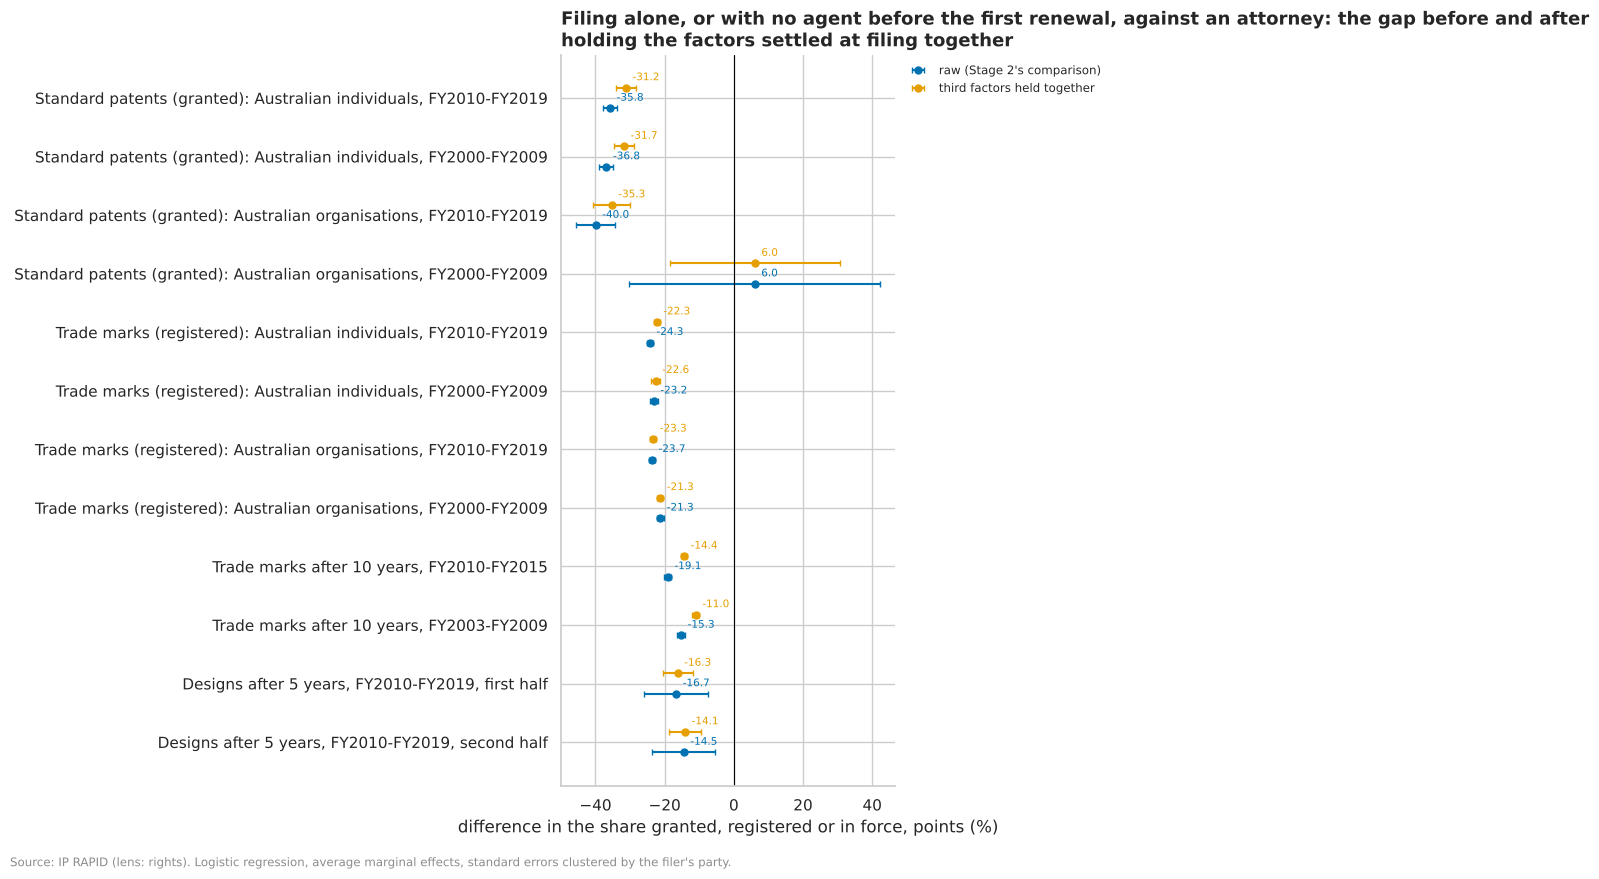

In [5]:
# the main reading of each sample (the rows with a field, examined or by filer type are in the tables above)
main = pd.concat([rep, renew])
main = main[~main.index.str.contains(", with a field|, examined|, individuals$|, organisations$", regex=True)]
fig = multi.effects_chart(
    main,
    title="Filing alone, or with no agent before the first renewal, against an attorney: the gap before and after\n"
    "holding the factors settled at filing together",
    xlabel="difference in the share granted, registered or in force, points",
    raw_name="raw (Stage 2's comparison)",
)
style.source(
    fig,
    "IP RAPID (lens: rights). Logistic regression, average marginal effects, standard errors clustered by the filer's"
    " party.",
)

#### Observations

**M1 (observational). Standard patents filed alone are granted far less often, and most of the gap stays when the
factors settled at filing are held together, for Australian individuals in both decades; trade marks likewise for
individuals and organisations.** Difference in the share granted or registered, filed alone minus with an attorney,
in points (raw; with the route, filing year, state and founders held together), with 95% intervals clustered by the
filer:
- **Australian individuals' standard patents:** FY2010 to FY2019, raw -35.8 (-37.8 to -33.8), held together -31.2
  (-34.0 to -28.4), 87.2% of the raw gap remaining; FY2000 to FY2009, -36.8 (-38.9 to -34.8) and -31.7 (-34.5 to
  -29.0), 86.2%. **Holds** in both decades. Among applications with a field, with the field and number of classes
  held too: -27.2 (-30.5 to -23.9) and -27.8 (-31.0 to -24.7). Among examined applications: -30.5 (-35.9 to -25.1)
  and -29.1 (-34.0 to -24.2).
- **Australian organisations' standard patents** hold in FY2010 to FY2019 (raw -40.0, -45.6 to -34.4; held together
  -35.3, -40.6 to -30.0), but not in FY2000 to FY2009: raw +6.0 (-30.2 to 42.3), held together +6.0 (-18.5 to 30.6),
  **not detected once held**; among examined applications that decade, alone is granted more often (+17.2, 0.6 to
  33.8). Clustering shows why the earlier decade differs: its 1,149 lone applications came from 392 filers, the ten
  largest filing 59.8% of them, against 10.1% of the later decade's 685 (543 filers). B6's guess that these were
  firms with their own patent staff fits a few heavy filers, but the data do not say who they were.
- **Trade marks** (with the Nice class and number of classes held too): Australian individuals -24.3 raw, -22.3
  (-23.2 to -21.5) held together, then -23.2 and -22.6 (-23.8 to -21.4); Australian organisations -23.7 and -23.3
  (-24.1 to -22.6), then -21.3 and -21.3 (-22.2 to -20.4). **Holds** in both decades, 91.9% to 99.9% remaining: the
  route, class, year, state and filers' number account for almost none of it.
- Lone filing is spread thinly: the ten heaviest lone filers hold 0.8% to 10.1% of the lone filings in every group but
  the older organisations', so the gap is not a few filers' (Australian individuals' patents: 1,642 lone applications
  from 1,370 filers).
- **Not a cause.** What is held fixed is what is known at filing; the filer's resources, experience and the merit of
  the invention are not in the data, and an application dropped early may never appoint an attorney (the arrow can run
  backwards, B6). The signal for Q4 is that the gap is not explained by the route, year, place, field or co-filers.

**M2 (observational). No agent before the first renewal goes with fewer trade marks and designs in force after it,
and most of the gap stays with the factors settled at filing held together, within individuals and organisations
alike.** Difference in the share in force after the renewal, no agent before it minus an attorney before it, in
points (raw; with the filer's type, class, number of classes, state, founders, route and cohort held together):
- **Trade marks after 10 years:** FY2010 to FY2015, 31.7% against 50.8%, raw -19.1 (-20.1 to -18.0), held together
  -14.4 (-15.4 to -13.4), 75.5% remaining; FY2003 to FY2009, 34.5% against 49.7%, -15.3 and -11.0 (-12.1 to -9.9),
  72.2%. **Holds** in both. Within each filer type it holds more fully (85.3% to 94.6% remaining): individuals -11.8
  (-13.3 to -10.3) and -12.0 (-13.8 to -10.3), organisations -15.1 (-16.3 to -13.9) and -10.8 (-12.1 to -9.6). Part
  of the pooled gap is who files alone (individuals, whose marks are less often in force either way: 22.3% and 35.6%
  in FY2010 to FY2015).
- **Designs after 5 years** (FY2010 to FY2019, first half then second): 30.0% against 46.7%, raw -16.7 (-25.9 to
  -7.5), held together -16.3 (-20.6 to -11.9); 32.4% against 46.8%, -14.5 and -14.1 (-18.8 to -9.4). **Holds** in both
  halves, 97.4% and 97.6% remaining, and within individuals (-13.4 and -13.3) and organisations (-16.8 and -13.9).
- B10's raw figures are reproduced (31.7% against 50.8%). **Not a cause:** an owner who means to let a mark go may
  not appoint an agent before the renewal, so the arrow can run backwards here too; and a share in force is not a
  renewal decision or value (U36, ADR 0041).

### 1.3 Reach, citations and the share in force, by origin, with field, route and cohort held together

**Revisits:** B8, B11, B12, B55. **Informs:** Q1. Stage 2 found three signals that disagree: Australian organisations'
standard patents reach fewer offices (B11) and are cited less, mostly because of that reach (B12), yet within the same
reach they are more often still in force at 10 years than overseas organisations' (B8, read only within reach bands at
the owner's word, A22). Here each is modelled with the **technology field**, the **route**, the **cohort**, **several
founding applicants** and the **number of classes** held together, and the share in force also with **reach** held.

- **In force to 10 years** (B8): granted standard patents, cohorts by the financial year of the date of patent, FY2010
  to FY2016 (the latest that have reached 10 years), in its two halves; FY2005 to FY2009 is shown as a provisional
  third reading, because older families' reach is incomplete (B55). Read as Stage 2's survival curves read it (ADR
  0041): each patent joins the count at its grant (delayed entry) and is followed from its date of patent to 10 years.
  The model is a **proportional hazards (Cox) model**, reported as a **hazard ratio**: the chance that a patent ends
  in any given year, Australian organisations' against overseas organisations', with the other factors held; 0.8
  means 20% less likely to end, so more often still in force. A hazard ratio is not a difference in shares, so the
  raw figure here is not B8's percentages, but the two read the same way.
- **Reach** (B11): the share of patents filed only in Australia, and in five or more offices, for standard patents
  filed FY2010 to FY2019 with a known family, in its two halves.
- **Citations within five years** (B12, with the final review's fixed-age window): the number of patent families that
  cite the family and were first filed within five years of its first priority, for families first filed by 22 April
  2020, as rate ratios from a negative binomial model (Australian against overseas organisations: 0.8 means 20% fewer
  citations).

Australian against overseas organisations throughout (individuals left out, as in B8); standard errors clustered by
the filer's party.

In [6]:
# (a) in force at 10 years, by origin, pooled with reach held and within each reach band
life_samples = {
    "FY2010-FY2016, first half": f"{DOP_FY} BETWEEN 2010 AND 2016 AND {HALF}",
    "FY2010-FY2016, second half": f"{DOP_FY} BETWEEN 2010 AND 2016 AND NOT {HALF}",
    "FY2005-FY2009 (provisional)": f"{DOP_FY} BETWEEN 2005 AND 2009",
}
LIFE_CONTROLS = ["field", "route", "cohort", "founders", "classes"]
rows, mix = [], []
for name, where in life_samples.items():
    d = org_rows(f"{LIFETIME}, {DOP_FY} AS cohort", f"{LIFE} AND {where}")
    mix.append(
        pd.crosstab(d.australian, d.reach, normalize="index").assign(
            patents=d.groupby("australian").size(), sample=name
        )
    )
    r = multi.adjusted_hazard(
        d, "t", "ended", "entry", "australian", ["reach", *LIFE_CONTROLS], cluster="filer_party", horizon=10
    )
    rows.append(r.rename(f"all reach, reach held: {name}"))
    for band, sub in d.groupby("reach"):
        r = multi.adjusted_hazard(
            sub, "t", "ended", "entry", "australian", LIFE_CONTROLS, cluster="filer_party", horizon=10
        )
        rows.append(r.rename(f"{band}: {name}"))
life = pd.DataFrame(rows)
mix = pd.concat(mix).set_index("sample", append=True)
mix = (100 * mix.drop(columns="patents")).round(1).join(mix.patents)
mix.index = mix.index.set_levels(["overseas organisations", "Australian organisations"], level="australian")
display(mix)
HAZARD = ["rows", "ended", "with signal", "raw", "raw low", "raw high", "adjusted", "adjusted low", "adjusted high",
          "share of raw remaining", "rows merged", "verdict"]  # fmt: skip
life[HAZARD].round(3)

,,Australia only,five or more offices,reach unknown,two to four offices,patents
australian,sample,,,,,
overseas organisations,"FY2010-FY2016, first half",4.6,75.2,0,20.2,59319
Australian organisations,"FY2010-FY2016, first half",22.3,35.7,0.1,42,3212
overseas organisations,"FY2010-FY2016, second half",4.5,75.4,0,20.1,58950
Australian organisations,"FY2010-FY2016, second half",23.5,36.4,0,40.1,3250
overseas organisations,FY2005-FY2009 (provisional),10.4,72.7,NaN,16.9,67676
Australian organisations,FY2005-FY2009 (provisional),52.3,22.2,NaN,25.5,4828


,rows,ended,with signal,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"all reach, reach held: FY2010-FY2016, first half",61566,18650,3157,0.765,0.677,0.864,0.773,0.673,0.887,0.962,19,holds
"Australia only: FY2010-FY2016, first half",3229,637,693,1.1,0.876,1.382,0.959,0.732,1.256,-0.437,148,not detected either way
"five or more offices: FY2010-FY2016, first half",45130,13749,1129,0.728,0.61,0.868,0.71,0.59,0.853,1.08,0,holds
"reach unknown: FY2010-FY2016, first half",19,7,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few rows
"two to four offices: FY2010-FY2016, first half",13188,4257,1333,0.75,0.627,0.899,0.811,0.674,0.977,0.728,39,holds
"all reach, reach held: FY2010-FY2016, second half",61238,18485,3181,0.718,0.636,0.811,0.701,0.61,0.804,1.075,8,holds
"Australia only: FY2010-FY2016, second half",3195,683,733,0.896,0.712,1.127,0.73,0.546,0.976,2.861,128,appears once held
"five or more offices: FY2010-FY2016, second half",44998,13757,1160,0.666,0.551,0.805,0.648,0.531,0.79,1.069,47,holds
"reach unknown: FY2010-FY2016, second half",8,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few rows
"two to four offices: FY2010-FY2016, second half",13037,4044,1288,0.757,0.639,0.896,0.772,0.649,0.917,0.929,40,holds


In [7]:
# (b) reach: filed only in Australia, and in five or more offices; (c) citations within five years of priority
REACH_CONTROLS = ["field", "route", "filing_fy", "founders", "classes"]
rows, cites = [], []
for name, where in {"first half": HALF, "second half": f"NOT {HALF}"}.items():
    d = org_rows(
        "(family_offices = 1)::INT AS australia_only, (family_offices >= 5)::INT AS five_plus, filing_fy,"
        " family_citations_5y AS cites_5y",
        f"filing_fy BETWEEN 2010 AND 2019 AND family_offices IS NOT NULL AND {where}",
    )
    for outcome, label in (("australia_only", "filed only in Australia"), ("five_plus", "five or more offices")):
        r = multi.adjusted_effect(d, outcome, "australian", REACH_CONTROLS, cluster="filer_party")
        rows.append(r.rename(f"{label}: FY2010-FY2019, {name}"))
    c = d.dropna(subset=["cites_5y"])
    for model, rhs in (
        ("raw", "australian"),
        ("reach held", "australian + C(reach)"),
        (
            "reach, field, route, year, founders, classes held",
            "australian + C(reach) + " + " + ".join(f"C({x})" for x in REACH_CONTROLS),
        ),
    ):
        nb = multi.nb_rate_ratios(c, f"cites_5y ~ {rhs}", cluster="filer_party").loc[["australian"]]
        cites.append(
            nb.assign(
                sample=name,
                model=model,
                mean_au=c.cites_5y[c.australian == 1].mean(),
                mean_overseas=c.cites_5y[c.australian == 0].mean(),
            )
        )
reach = pd.DataFrame(rows)
display(reach[EFFECT].round(3))
pd.concat(cites).set_index(["sample", "model"])[
    ["rate ratio", "low", "high", "alpha", "rows", "mean_au", "mean_overseas", "converged"]
].round(3)

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"filed only in Australia: FY2010-FY2019, first half",127020,0.409,0.082,0.327,0.283,0.37,0.093,0.083,0.103,0.284,0,weakened
"five or more offices: FY2010-FY2019, first half",127020,0.222,0.697,-0.475,-0.515,-0.435,-0.319,-0.346,-0.293,0.673,0,holds
"filed only in Australia: FY2010-FY2019, second half",126525,0.405,0.082,0.322,0.274,0.37,0.102,0.091,0.112,0.316,0,weakened
"five or more offices: FY2010-FY2019, second half",126525,0.23,0.695,-0.464,-0.507,-0.422,-0.314,-0.341,-0.287,0.676,0,holds


rate ratio   low  high  alpha    rows  mean_au  mean_overseas  converged
sample      model                                                                                                                      
first half  raw                                                     0.312 0.272 0.359  1.852  127020    4.436          14.22       True
            reach held                                              0.645 0.577 0.721  1.483  127020    4.436          14.22       True
            reach, field, route, year, founders, classes held       0.729 0.677 0.784  1.258  127020    4.436          14.22       True
second half raw                                                     0.307 0.259 0.363  1.868  126525     4.43          14.44       True
            reach held                                              0.633 0.556  0.72  1.502  126525     4.43          14.44       True
            reach, field, route, year, founders, classes held         0.7 0.634 0.774  1.274  126525     4.43          14.44       True

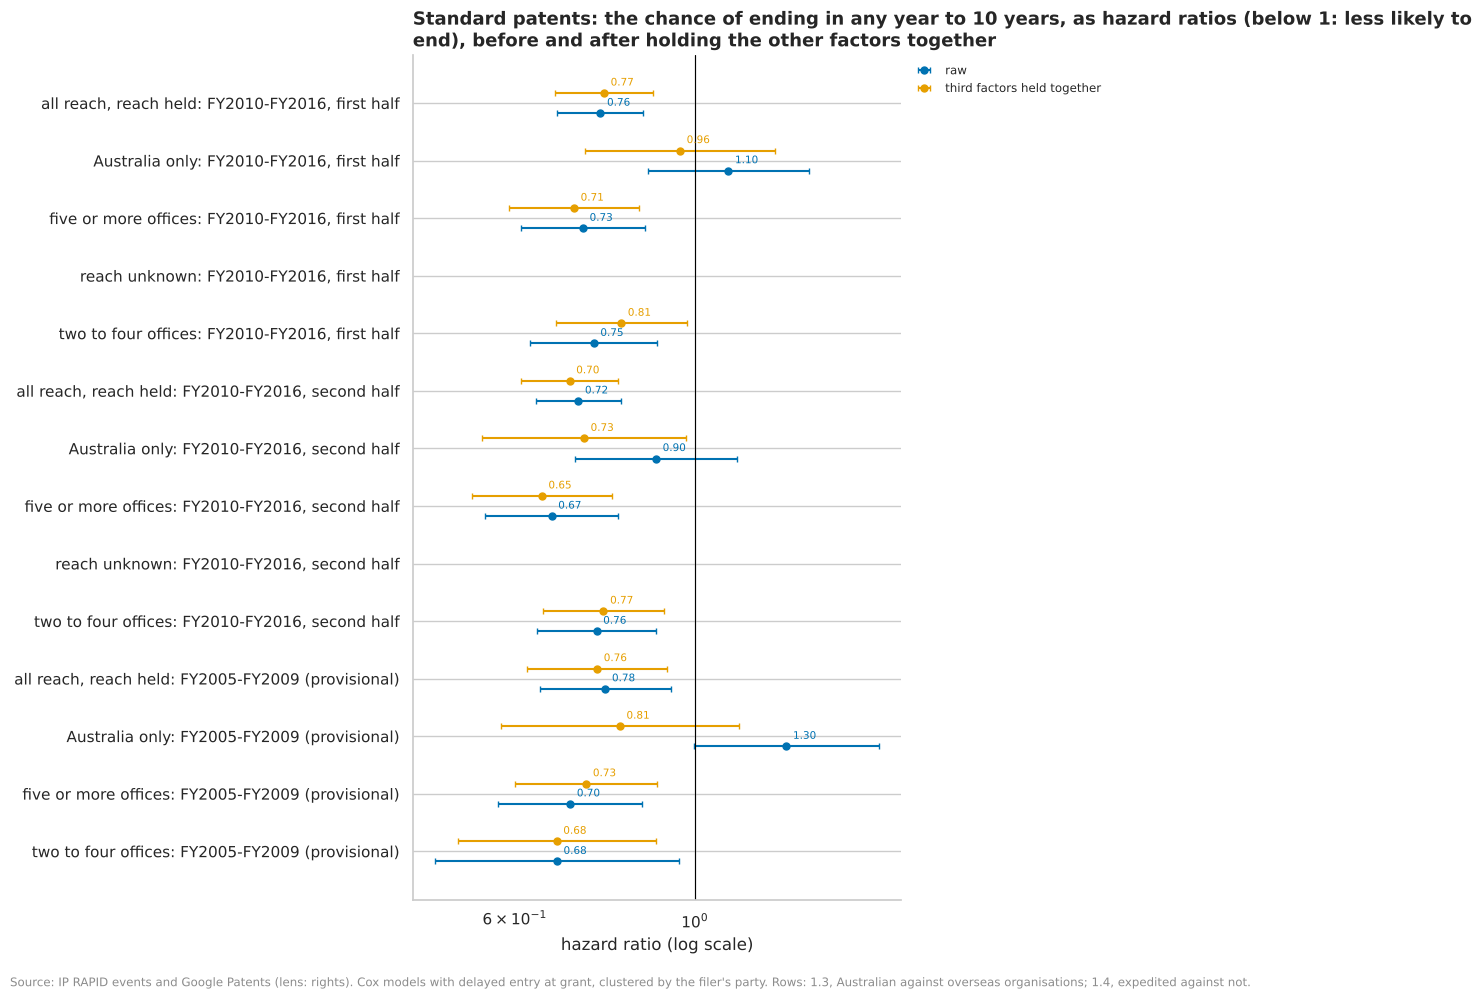

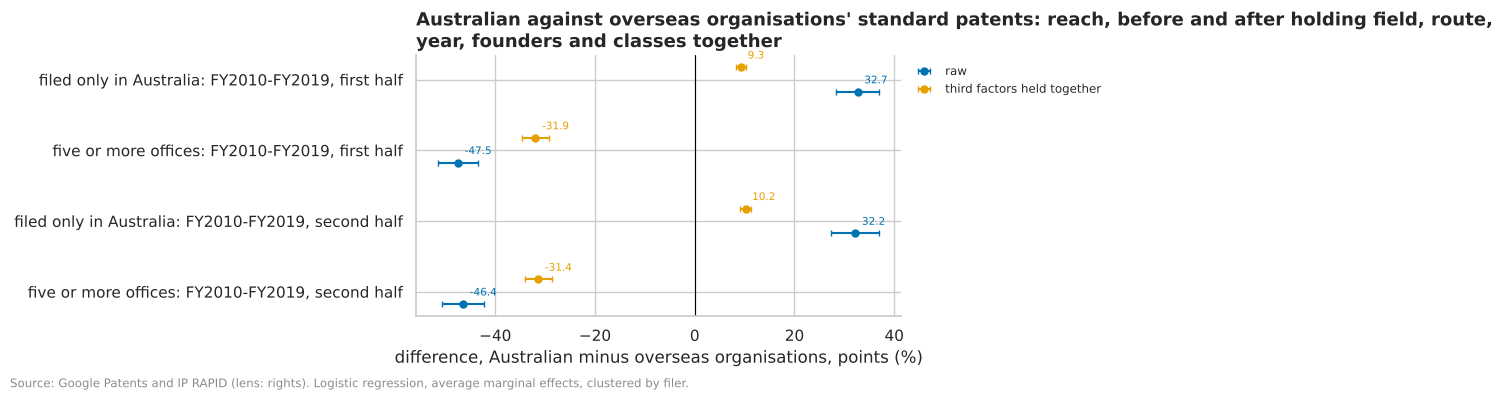

In [8]:
fig = multi.effects_chart(
    pd.concat([life, expedite]) if "expedite" in globals() else life,
    title="Standard patents: the chance of ending in any year to 10 years, as hazard ratios (below 1: less likely to\n"
    "end), before and after holding the other factors together",
    xlabel="hazard ratio (log scale)",
    percent=False,
    fmt="{:.2f}",
    null=1,
)
fig.axes[0].set_xscale("log")
style.source(
    fig,
    "IP RAPID events and Google Patents (lens: rights). Cox models with delayed entry at grant, clustered by the"
    " filer's party. Rows: 1.3, Australian against overseas organisations; 1.4, expedited against not.",
)
fig = multi.effects_chart(
    reach,
    title="Australian against overseas organisations' standard patents: reach, before and after holding field, route,\n"
    "year, founders and classes together",
    xlabel="difference, Australian minus overseas organisations, points",
)
style.source(
    fig,
    "Google Patents and IP RAPID (lens: rights). Logistic regression, average marginal effects, clustered by filer.",
)

#### Observations

**M3 (observational). Within the same reach, Australian organisations' standard patents are less likely to end in
any year to 10 years than overseas organisations', and the gap holds with the field, route, cohort, founders and
classes held together, in both halves; among Australia-only patents there is no consistent gap.** Hazard ratios,
Australian against overseas organisations (below 1: less likely to end), date of patent FY2010 to FY2016, first half
then second (raw; held together), with 95% intervals clustered by the filer:
- **Five or more offices:** 0.728 (0.610 to 0.868) and 0.710 (0.590 to 0.853); 0.666 (0.551 to 0.805) and 0.648
  (0.531 to 0.790). **Holds.**
- **Two to four offices:** 0.750 (0.627 to 0.899) and 0.811 (0.674 to 0.977); 0.757 (0.639 to 0.896) and 0.772
  (0.649 to 0.917). **Holds.**
- **Australia only:** 1.100 (0.876 to 1.382) and 0.959 (0.732 to 1.256), not detected either way; 0.896 (0.712 to
  1.127) and 0.730 (0.546 to 0.976), which appears once held in the second half only. The halves disagree, so B8's
  "no difference among Australia-only patents" is neither overturned nor confirmed.
- **All reach bands, reach held:** 0.773 (0.673 to 0.887) and 0.701 (0.610 to 0.804); in the provisional FY2005 to
  FY2009 cohorts, 0.758 (0.621 to 0.925).
- **Why reach must be held:** 22.3% and 23.5% of Australian organisations' granted patents are Australia only, against
  4.6% and 4.5% of overseas organisations'; 35.7% and 36.4% reach five or more offices, against 75.2% and 75.4%. The
  pooled raw ratio (0.765 and 0.718) is close to the one with reach held, because the in-band gaps point the same way.

**M4 (observational). Australian organisations' patents reach fewer offices and are cited less within five years of
priority; the field, route, year and the rest account for much of each gap, and reach for most of the citation gap,
but neither gap goes.** Standard patents filed FY2010 to FY2019, first half then second:
- **Filed only in Australia:** 40.9% of Australian organisations' against 8.2% of overseas organisations', raw +32.7
  points (28.3 to 37.0), held together +9.3 (8.3 to 10.3), 28.4% remaining; second half +32.2 and +10.2 (9.1 to
  11.2). **Weakened.**
- **Five or more offices:** 22.2% against 69.7%, raw -47.5 (-51.5 to -43.5), held together -31.9 (-34.6 to -29.3),
  67.3% remaining; second half -46.4 and -31.4 (-34.1 to -28.7). **Holds.**
- **Citations within five years** (the fixed-age window): on average 4.44 citing families for Australian
  organisations' patents against 14.22 for overseas organisations'. Rate ratio 0.312 (0.272 to 0.359) raw, 0.645
  (0.577 to 0.721) with reach held, 0.729 (0.677 to 0.784) with every factor held; second half 0.307, 0.633 and 0.700
  (0.634 to 0.774). On a log scale reach accounts for about three fifths of the raw gap (62% and 61%), and about 27%
  and 30% of it remains with every factor held: **weakened**, but about 27% to 30% fewer citations at the same reach,
  field, route and year.
- **So the three signals still disagree once held together:** fewer offices and fewer citations in the same field,
  route and year, yet more often in force at the same reach. None of them is value, private or public (A22, B8);
  they are three readings of how patents are used, to be read side by side. Reach is held only in three bands, so
  part of a gap within a band could still be reach.

### 1.4 Expedited examination and the share in force, with the filer, field, route and cohort held together

**Revisits:** B13. **Informs:** Q1, Q4. Stage 2 found expedited standard patents slightly more often in force at 10
years, pooled, in both periods (3.7 and 1.0 points), not explained by the mix of filers, but differing by filer. Here
the gap is modelled with the **filer** (origin and type), the **field**, the **route**, the **cohort**, **several
founding applicants** and the **number of classes** held together, among examined standard patents, with the same
hazard model as 1.3 (each patent counted from its grant, to 10 years; a hazard ratio below 1 means expedited patents
are less likely to end in a given year); cohorts by the date of patent as in B13 (FY2010 to FY2016, then FY2003 to
FY2009). The same model within
each filer group follows. Since 2014 "expedited" includes requests under work-sharing arrangements
(the Patent Prosecution Highway, OQ25), which IP RAPID does not tell apart.

In [9]:
EXPEDITE_CONTROLS = ["filer", "field", "route", "cohort", "founders", "classes"]
rows = []
for lo, hi in ((2010, 2016), (2003, 2009)):
    d = rsql(f"""
        WITH @FILER_PARTY
        SELECT {LIFETIME}, exam_expedited::INT AS expedited,
               filer_group AS filer, coalesce(main_area, 'unknown') AS field,
               coalesce(filing_route, 'unknown') AS route,
               {DOP_FY} AS cohort, CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
               CASE WHEN class_count IS NULL THEN 'unknown' WHEN class_count = 1 THEN '1' WHEN class_count <= 3
                    THEN '2-3' ELSE '4+' END AS classes,
               coalesce(filer_party, application_number) AS filer_party
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE patent_type = 'standard' AND filer_group IS NOT NULL AND exam_expedited IS NOT NULL AND {LIFE}
          AND {DOP_FY} BETWEEN {lo} AND {hi}
        ORDER BY hash(application_number || 'stage3'), application_number
        LIMIT 200000
    """)
    name = f"FY{lo}-FY{hi}"
    r = multi.adjusted_hazard(
        d, "t", "ended", "entry", "expedited", EXPEDITE_CONTROLS, cluster="filer_party", horizon=10
    )
    rows.append(r.rename(f"all filers: {name}"))
    for fg, sub in d.groupby("filer"):
        r = multi.adjusted_hazard(
            sub, "t", "ended", "entry", "expedited", EXPEDITE_CONTROLS[1:], cluster="filer_party", horizon=10
        )
        rows.append(r.rename(f"{fg.replace('_', ' ')}s: {name}"))
expedite = pd.DataFrame(rows)
expedite[HAZARD].round(3)

,rows,ended,with signal,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
all filers: FY2010-FY2016,130120,39638,8971,0.958,0.842,1.091,1.021,0.902,1.156,-0.495,0,not detected either way
australian individuals: FY2010-FY2016,1363,415,339,1.341,1.086,1.656,1.264,1.013,1.576,0.797,287,holds
australian organisations: FY2010-FY2016,6336,1471,919,0.992,0.838,1.175,0.989,0.836,1.17,1.343,59,not detected either way
overseas individuals: FY2010-FY2016,5959,2089,543,1.077,0.93,1.248,1.07,0.92,1.244,0.908,12,not detected either way
overseas organisations: FY2010-FY2016,116462,35663,7170,0.945,0.805,1.11,1.004,0.863,1.169,-0.076,0,not detected either way
all filers: FY2003-FY2009,104148,28548,6737,0.782,0.717,0.853,1.124,1.03,1.228,-0.476,0,reversed
australian individuals: FY2003-FY2009,1889,642,553,1.344,1.141,1.582,1.249,1.053,1.481,0.751,158,holds
australian organisations: FY2003-FY2009,6473,1401,1139,1.146,0.934,1.405,1.285,1.046,1.58,1.847,42,appears once held
overseas individuals: FY2003-FY2009,5596,1785,271,1.329,1.07,1.651,1.721,1.378,2.149,1.907,24,holds
overseas organisations: FY2003-FY2009,90190,24720,4774,0.598,0.537,0.665,0.957,0.862,1.063,0.085,0,not detected once held


#### Observations

**M5 (observational). Expedited examination's link with a longer life does not survive the other factors: pooled, it
is not detected once the filer, field, route and cohort are held (FY2010 to FY2016) and reverses (FY2003 to FY2009);
among Australian individuals, expedited patents are more likely to end, in both periods.** Hazard ratios, expedited
against not (below 1: less likely to end), to 10 years from the date of patent (raw; held together):
- **All filers:** FY2010 to FY2016, 0.958 (0.842 to 1.091) and 1.021 (0.902 to 1.156), not detected either way;
  FY2003 to FY2009, 0.782 (0.717 to 0.853) and 1.124 (1.030 to 1.228), **reversed**. The earlier period's raw
  advantage (B13's 3.7 points) is accounted for by what is held: B13 found it was not the mix of filers, and here the
  field, route, cohort, founders and classes held with the filer take it away. **Revisits B13**, whose "not a
  composition effect" held for the filer mix only.
- **Overseas organisations** (most of the patents): 0.945 (0.805 to 1.110) and 1.004 (0.863 to 1.169), then 0.598
  (0.537 to 0.665) and 0.957 (0.862 to 1.063): **not detected once held** in the earlier period.
- **Australian individuals:** 1.341 (1.086 to 1.656) and 1.264 (1.013 to 1.576), then 1.344 (1.141 to 1.582) and
  1.249 (1.053 to 1.481): **holds** in both periods, expedited patents about a quarter more likely to end in a given
  year. B13 found the same direction in shares (59.7% against 68.5%, then 55.1% against 65.0%).
- **Australian organisations:** 0.992 and 0.989 (0.836 to 1.170), not detected either way; then 1.146 (0.934 to
  1.405) and 1.285 (1.046 to 1.580), appears once held. **Overseas individuals:** 1.077 and 1.070 (0.920 to 1.244),
  not detected either way; then 1.329 (1.070 to 1.651) and 1.721 (1.378 to 2.149), holds.
- **So** expedited examination is not a sign of a patent that lasts longer, once who files, the field and the route
  are known; for Australian individuals it goes with a shorter life. One reading, to test: an individual who asks for
  speed may want a granted patent quickly (to show investors or licensees) and let it go if nothing comes of it. Since
  2014 "expedited" also includes work-sharing requests (OQ25), so the kinds of request are mixed.

### 1.5 Australian-founded patents now held only overseas: reach, grant and the filer's type held together

**Revisits:** B19. **Informs:** Q1. Stage 2 found that Australian-founded standard patents now held only overseas
(two endpoints: the founding applicant in Australia, every current holder overseas; not a transfer history, ADR 0040)
are commoner among the wide (five or more offices), the granted and organisations' patents. The three go together
(wide patents are more often granted, and organisations' are wider), so each is read here with the other two held,
and the **field**, **route**, **filing year** and **several founding applicants** with them. Filed FY2003 to FY2011,
then FY2012 to FY2021 (which have had less time to change hands), as in B19; reach compares five or more offices with
Australia only (two to four offices held as their own band in the other readings). Clustered by the filer's party.

In [10]:
OVERSEAS_COLUMNS = f"""
    (NOT australian_applicant)::INT AS held_overseas, {REACH} AS reach,
    (registered_date IS NOT NULL)::INT AS granted,
    (split_part(filer_group, '_', 2) = 'organisation')::INT AS organisation,
    coalesce(main_area, 'unknown') AS field, coalesce(filing_route, 'unknown') AS route, filing_fy,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    coalesce(filer_party, application_number) AS filer_party"""
rows = []
for lo, hi in ((2003, 2011), (2012, 2021)):
    d = rsql(f"""
        WITH @FILER_PARTY
        SELECT {OVERSEAS_COLUMNS}
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE patent_type = 'standard' AND founding_australian AND filer_group IS NOT NULL
          AND australian_applicant IS NOT NULL AND filing_fy BETWEEN {lo} AND {hi}
    """)
    name = f"FY{lo}-FY{hi}"
    base = ["field", "route", "filing_fy", "founders"]
    wide = d[d.reach.isin(["Australia only", "five or more offices"])].assign(
        wide=lambda x: (x.reach == "five or more offices").astype(int)
    )
    rows.append(
        multi.adjusted_effect(
            wide, "held_overseas", "wide", ["granted", "organisation", *base], cluster="filer_party"
        ).rename(f"five or more offices (against Australia only): {name}")
    )
    rows.append(
        multi.adjusted_effect(
            d, "held_overseas", "granted", ["reach", "organisation", *base], cluster="filer_party"
        ).rename(f"granted (against never granted): {name}")
    )
    rows.append(
        multi.adjusted_effect(
            d, "held_overseas", "organisation", ["reach", "granted", *base], cluster="filer_party"
        ).rename(f"organisation (against individual): {name}")
    )
overseas = pd.DataFrame(rows)
overseas[EFFECT].round(4)

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
five or more offices (against Australia only): FY2003-FY2011,17262,0.1452,0.0375,0.1076,0.0423,0.173,0.0432,0.0275,0.0588,0.4011,126,weakened
granted (against never granted): FY2003-FY2011,23216,0.0996,0.0115,0.0881,0.0331,0.1432,0.0563,0.0459,0.0668,0.6393,740,holds
organisation (against individual): FY2003-FY2011,23216,0.0691,0.0157,0.0534,0.0131,0.0937,0.0262,0.015,0.0373,0.4902,740,weakened
five or more offices (against Australia only): FY2012-FY2021,16088,0.0625,0.0116,0.0509,0.0383,0.0636,0.0222,0.0115,0.033,0.4368,85,weakened
granted (against never granted): FY2012-FY2021,25819,0.0481,0.0087,0.0394,0.0322,0.0465,0.0277,0.0217,0.0337,0.7036,130,holds
organisation (against individual): FY2012-FY2021,25819,0.0284,0.0181,0.0102,0.0034,0.0171,0.0005,-0.0079,0.009,0.0523,130,not detected once held


#### Observations

**M6 (observational). Australian-founded patents now held only overseas are commoner among the granted, with reach and
the filer's type held; the wide patents' higher rate is more than halved once grant and type are held, and the
organisations' gap goes in the later period.** Difference in the share now held only overseas, in points (raw; held
together, with the field, route, filing year and founders), filed FY2003 to FY2011 then FY2012 to FY2021:
- **Granted against never granted:** +8.8 (3.3 to 14.3) and +5.6 (4.6 to 6.7); +3.9 (3.2 to 4.7) and +2.8 (2.2 to
  3.4). **Holds** in both, 63.9% and 70.4% remaining.
- **Five or more offices against Australia only:** +10.8 (4.2 to 17.3) and +4.3 (2.8 to 5.9); +5.1 (3.8 to 6.4) and
  +2.2 (1.2 to 3.3). **Weakened** in both, 40.1% and 43.7% remaining: much of the wide patents' higher rate goes with
  their being granted and organisations'.
- **Organisations against individuals:** +5.3 (1.3 to 9.4) and +2.6 (1.5 to 3.7), weakened; +1.0 (0.3 to 1.7) and
  +0.05 (-0.8 to 0.9), **not detected once held** in the later period.
- The raw intervals in the earlier period are wide (clustered by filer): a few filers hold many of these patents.
  The later period has had less time for holders to change (B19).
- **Two endpoints, not transfers** (ADR 0040): grant and reach are seen today, not necessarily before the holder
  changed, and nothing here says where value goes. The signal for Q1 is that granted Australian-founded patents are
  the ones more often held only overseas now, whatever their reach and filer.

### 1.6 Women among inventors: the filer, with the field and year held together

**Revisits:** B17, B18. **Informs:** Q2. Stage 2 found that the field matters more than the filer for women among
inventors in Australia on standard patents (4.2% to 26.9% by field; the filer gap did not replicate), and that on
provisional applications Australian organisations' inventors include more women than Australian individuals' (21.19%
against 16.12%, FY2013 to FY2022). Its named third factor was the field, which the two filer groups may weight
differently. Here each patent's estimated share of women among its inventors is modelled, weighted by its inventors
with an estimate (a quasi-binomial model), Australian organisations against Australian individuals:

- **standard patents** (inventors in Australia, from Google Patents, as in B17), with the **field**, **filing year**
  and **state** held together, FY2010 to FY2019 then FY2000 to FY2009;
- **provisionals** (the register's inventors, with the applicant's country, as in B18), with the **filing year**,
  **state** and **several founding applicants** held together, FY2013 to FY2022 then FY2003 to FY2012. Provisionals
  have no technology field in IP RAPID, so the field cannot be held for them.

Expected counts from first names, read for inventors in Australia only (U97); clustered by the filer's party.

In [11]:
std = rsql(
    """
    WITH @FILER_PARTY
    SELECT r.application_number, @PERIOD AS period, (r.filer_group = 'australian_organisation')::INT AS organisation,
           coalesce(r.main_area, 'unknown') AS field, r.filing_fy, coalesce(r.founder_state, 'unknown') AS state,
           coalesce(p.filer_party, r.application_number) AS filer_party,
           sum(i.p_female) / count(i.p_female) AS women_share, count(i.p_female) AS estimated
    FROM {lens/rights} r JOIN {google_patents_inventors/inventors} i USING (family_id)
         LEFT JOIN filer_party p USING (ip_right_type, application_number)
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2000 AND 2019 AND i.country_code = 'AU'
      AND r.filer_group IN ('australian_individual', 'australian_organisation') AND i.p_female IS NOT NULL
    GROUP BY ALL
"""
)
prov = rsql("""
    WITH @FILER_PARTY
    SELECT CASE WHEN filing_fy BETWEEN 2013 AND 2022 THEN 'FY2013-FY2022' ELSE 'FY2003-FY2012' END AS period,
           (filer_group = 'australian_organisation')::INT AS organisation, filing_fy,
           coalesce(founder_state, 'unknown') AS state,
           CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
           coalesce(filer_party, application_number) AS filer_party,
           register_inventors_women_expected / (register_inventors - register_inventors_gender_unknown) AS women_share,
           register_inventors - register_inventors_gender_unknown AS estimated
    FROM {lens/rights} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
    WHERE patent_type = 'provisional' AND filing_fy BETWEEN 2003 AND 2022
      AND filer_group IN ('australian_individual', 'australian_organisation')
      AND register_inventors - register_inventors_gender_unknown > 0
""")
rows = []
for period, d in std.groupby("period", sort=False):
    rows.append(
        multi.adjusted_effect(
            d,
            "women_share",
            "organisation",
            ["field", "filing_fy", "state"],
            cluster="filer_party",
            weights="estimated",
        ).rename(f"standard patents: {period}")
    )
for period, d in prov.groupby("period", sort=False):
    rows.append(
        multi.adjusted_effect(
            d,
            "women_share",
            "organisation",
            ["filing_fy", "state", "founders"],
            cluster="filer_party",
            weights="estimated",
        ).rename(f"provisionals: {period}")
    )
women = pd.DataFrame(rows).sort_index()
print(
    f"Standard patents: {len(std):,}, {std.estimated.sum():,} inventors with an estimate;",
    f"provisionals: {len(prov):,}, {prov.estimated.sum():,.0f}",
)
women[EFFECT].round(4)

Standard patents: 18,182, 35,446 inventors with an estimate; provisionals: 110,717, 140,492


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
provisionals: FY2003-FY2012,63728,0.2551,0.189,0.0662,0.054,0.0783,0.0663,0.0548,0.0778,1.002,0,holds
provisionals: FY2013-FY2022,46989,0.2119,0.1612,0.0507,0.0377,0.0638,0.0556,0.0426,0.0687,1.097,0,holds
standard patents: FY2000-FY2009,4762,0.159,0.1122,0.0468,-0.0112,0.1048,-0.0212,-0.0535,0.0112,-0.4523,23,not detected either way
standard patents: FY2010-FY2019,13420,0.1218,0.1113,0.0105,-0.0065,0.0275,-0.0282,-0.0458,-0.0107,-2.685,0,appears once held


#### Observations

**M7 (observational). On provisionals, Australian organisations' inventors include more women than Australian
individuals', and the gap holds with the year, state and founders held, in both decades; on standard patents, the
organisations' apparent advantage is the field: with the field held, organisations' inventors include fewer women in
FY2010 to FY2019.** Difference in the estimated share of women among inventors, Australian organisations minus
Australian individuals, in points (raw; held together), weighted by inventors with an estimate:
- **Provisionals** (the register's inventors; 110,717 provisionals, 140,492 inventors with an estimate): FY2013 to
  FY2022, 21.19% against 16.12%, raw +5.07 (3.77 to 6.38), held together +5.56 (4.26 to 6.87); FY2003 to FY2012,
  25.51% against 18.90%, +6.62 (5.40 to 7.83) and +6.63 (5.48 to 7.78). **Holds** in both. The field cannot be held
  for provisionals (none has one in IP RAPID).
- **Standard patents** (inventors in Australia; 18,182 patents, 35,446 inventors with an estimate): FY2010 to FY2019,
  12.18% against 11.13%, raw +1.05 (-0.65 to 2.75), held together -2.82 (-4.58 to -1.07), which **appears once held**;
  FY2000 to FY2009, 15.90% against 11.22%, +4.68 (-1.12 to 10.48) and -2.12 (-5.35 to 1.12), not detected either way.
  B17's filer gap (15.9% against 11.22%, with intervals that did not overlap) is not detected once the filer is
  clustered, and turns negative with the field held.
- **So** B17's reading, that the field matters more than the filer, is confirmed: within the same field and year,
  organisations' patents name no more women than individuals', and in the later decade fewer. The provisional gap
  stands but cannot be checked against the field. Expected counts from first names, levels for inventors in Australia
  only (U97); the provisionals' estimates use the applicant's country (B18).

### 1.7 Summary of the rights lens

| Stage 2 signal | Stage 3 | What is left once the third factors are held together |
|---|---|---|
| B6: filing alone and grant | M1 | **Holds** for Australian individuals in both decades (about 31 points, 86% to 87% of the raw gap) and for trade marks (21 to 23 points); for Australian organisations only in FY2010 to FY2019 |
| B10: no agent before the first renewal | M2 | **Holds** for trade marks (11 to 14 points) and designs (14 to 16 points), within individuals and organisations |
| B8, B11, B12: reach, citations and life, by origin | M3, M4 | Less likely to end within the same reach (**holds**, hazard ratios 0.65 to 0.81); fewer offices (**holds**) and fewer citations (**weakened**: about 27% to 30% fewer at the same reach, field, route and year) |
| B13: expedited examination and life | M5 | **Not detected once held**, pooled; **reversed** in FY2003 to FY2009; Australian individuals' expedited patents more likely to end (**holds**) |
| B19: Australian-founded, now held only overseas | M6 | Granted patents (**holds**); wide patents (**weakened**); organisations (weakened, then not detected) |
| B17, B18: women among inventors | M7 | Provisionals: organisations' inventors include more women (**holds**); standard patents: the field accounts for the organisations' apparent advantage |

**Revisits for the atlas** (listed in the handover, not changed while it is frozen): B13 (its pooled link does not
survive the field, route and cohort) and B17 (its filer gap is not detected with the filer clustered, and turns
negative with the field held).

## 2. Lens: Firms (one row per ABN)

Stage 2's shorthands carry over: a firm **has a filing linked** if `ip_record` is "filed" (ADR 0036; "no filing
linked", never "never filed", since IP RAPID leaves many recent filers without an ABN, U45); the two samples are the
**halves** of `bi.half_sql` on the ABN; and **age** is on the record at the corpus build date, with undated firms and
those first seen before 2001 as their own groups, never read as old (ADR 0039). One row is one firm, so no clustering
is needed.

In [12]:
FILED = "(ip_record = 'filed')"
FIRM_HALF = f"CASE WHEN {bi.half_sql('abn')} THEN 'first half' ELSE 'second half' END"
AGE = (
    "CASE WHEN first_seen IS NULL THEN 'no registration date' "
    "WHEN age_truncated THEN 'first seen before 2001 (may be older)' WHEN age_years < 3 THEN 'under 3 years'"
    " WHEN age_years < 10 THEN '3 to 10 years' WHEN age_years < 20 THEN '10 to 20 years' ELSE '20 years or more' END"
)
FIRM_COLUMNS = f"""
    {FIRM_HALF} AS half, {FILED}::INT AS filed, (n_patents_standard > 0)::INT AS patent,
    (n_trade_marks > 0)::INT AS trade_mark, coalesce(entity_group, 'unknown') AS entity_group, {AGE} AS age,
    coalesce(state, 'unknown') AS state, coalesce(remoteness, 'unknown') AS remoteness,
    coalesce(irsad_decile::VARCHAR, 'unknown') AS irsad_decile"""

### 2.1 Who files among R&D Tax Incentive claimants: spend, company form, age and place held together

**Revisits:** B22, B23. **Informs:** Q2, Q3, Q4. Stage 2 found that, among R&D Tax Incentive claimants, filing goes
with company form, age and cities, that R&D spend goes only weakly with patenting, and that about half of claimants
have no filing linked, mostly private companies of 3 to 10 years. Each of four signals is modelled here with the
others held together (and the state and the advantage of the postcode, its IRSAD decile): **R&D spend** (an average
claim above the claimants' median), **company form** (a public against a private company), **age** (20 years or more
against 3 to 10) and **place** (a major city against elsewhere). Two outcomes: any filing linked, and a standard
patent filed. Active ABNs that claimed in 2021-22 to 2023-24 with a recorded spend, in each half. The R&D Tax
Incentive covers companies only, so the form compares kinds of company.

In [13]:
rd = sql(
    f"""
    SELECT {FIRM_COLUMNS}, rd_expenditure_mean,
           (rd_expenditure_mean > median(rd_expenditure_mean) OVER ())::INT AS high_spend
    FROM {{lens/firms}} WHERE abn_active AND in_rdti AND rd_expenditure_mean > 0
""",
    max_rows=None,
)
rd["public"] = (rd.entity_group == "Public company").astype(int)
rd["old"] = (rd.age == "20 years or more").astype(int)
rd["city"] = (rd.remoteness == "Major Cities of Australia").astype(int)
print(
    f"Claimants: {len(rd):,}; median average claim ${rd.rd_expenditure_mean.median():,.0f};",
    "entity groups:",
    rd.entity_group.value_counts().to_dict(),
)
SIGNALS = {
    "high_spend": ("R&D spend above the median", ["entity_group", "age", "remoteness"], None),
    "public": (
        "public against private company",
        ["high_spend", "age", "remoteness"],
        ["Public company", "Private company"],
    ),
    "old": (
        "20 years or more against 3 to 10",
        ["high_spend", "entity_group", "remoteness"],
        ["20 years or more", "3 to 10 years"],
    ),
    "city": ("major city against elsewhere", ["high_spend", "entity_group", "age"], None),
}
rows = []
for outcome, oname in (("filed", "any filing linked"), ("patent", "a standard patent")):
    for sig, (sname, others, keep) in SIGNALS.items():
        for half, d in rd.groupby("half"):
            sub = d if keep is None else d[d.entity_group.isin(keep) if sig == "public" else d.age.isin(keep)]
            r = multi.adjusted_effect(sub, outcome, sig, [*others, "state", "irsad_decile"])
            rows.append(r.rename(f"{oname}: {sname}, {half}"))
rd_effects = pd.DataFrame(rows)
rd_effects[EFFECT].round(3)

Claimants: 17,514; median average claim $326,125; entity groups: {'Private company': 16510, 'Public company': 969, 'Other': 30, 'Trust': 3, 'Partnership': 2}


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"any filing linked: R&D spend above the median, first half",8841,0.545,0.485,0.06,0.039,0.081,0.024,0.003,0.045,0.408,93,weakened
"any filing linked: R&D spend above the median, second half",8673,0.552,0.489,0.064,0.043,0.085,0.028,0.007,0.049,0.439,87,weakened
"any filing linked: public against private company, first half",8820,0.638,0.508,0.13,0.085,0.175,0.059,0.01,0.108,0.453,70,weakened
"any filing linked: public against private company, second half",8659,0.647,0.513,0.134,0.091,0.177,0.064,0.018,0.111,0.478,68,weakened
"any filing linked: 20 years or more against 3 to 10, first half",6082,0.674,0.432,0.242,0.215,0.268,0.231,0.203,0.259,0.956,59,holds
"any filing linked: 20 years or more against 3 to 10, second half",5924,0.666,0.437,0.229,0.203,0.256,0.224,0.196,0.252,0.977,51,holds
"any filing linked: major city against elsewhere, first half",8841,0.52,0.469,0.052,0.017,0.086,0.056,0.017,0.096,1.085,56,holds
"any filing linked: major city against elsewhere, second half",8673,0.523,0.501,0.022,-0.013,0.056,0.005,-0.034,0.045,0.252,52,not detected either way
"a standard patent: R&D spend above the median, first half",8841,0.154,0.092,0.062,0.048,0.075,0.043,0.029,0.057,0.697,93,holds
"a standard patent: R&D spend above the median, second half",8673,0.161,0.094,0.066,0.052,0.08,0.047,0.033,0.061,0.712,87,holds


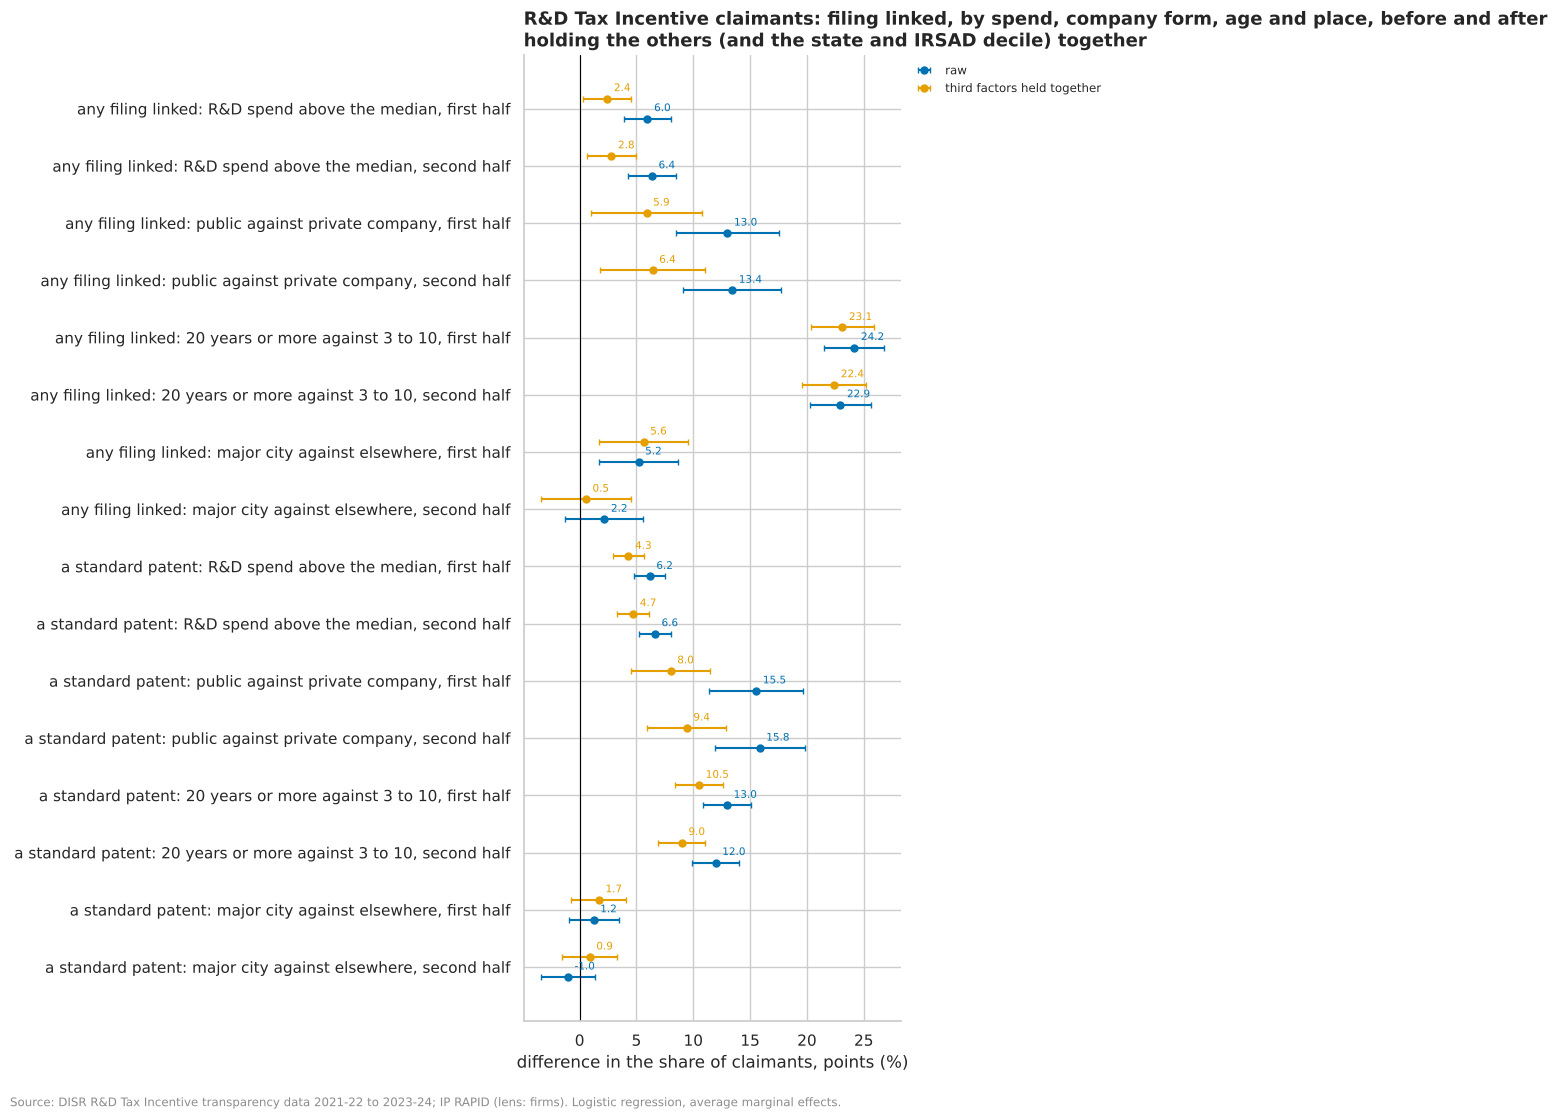

In [14]:
fig = multi.effects_chart(
    rd_effects,
    title="R&D Tax Incentive claimants: filing linked, by spend, company form, age and place, before and after\n"
    "holding the others (and the state and IRSAD decile) together",
    xlabel="difference in the share of claimants, points",
)
style.source(
    fig,
    "DISR R&D Tax Incentive transparency data 2021-22 to 2023-24; IP RAPID (lens: firms). Logistic"
    " regression, average marginal effects.",
)

#### Observations

**M8 (observational). Among R&D Tax Incentive claimants, age goes with having a filing linked almost as strongly with
spend, form and place held; higher R&D spend and being a public company go with a standard patent, held together,
but less with any filing; the city gap does not replicate.** 17,514 active claimants with a recorded spend (median
average claim $326,125; 16,510 private and 969 public companies). Difference in the share of claimants, in points
(raw; held together, with the state and IRSAD decile), first half then second:
- **20 years or more against 3 to 10:** any filing linked +24.2 (21.5 to 26.8) and +23.1 (20.3 to 25.9); +22.9 and
  +22.4 (19.6 to 25.2). A standard patent +13.0 and +10.5 (8.4 to 12.6); +12.0 and +9.0 (6.9 to 11.1). **Holds.**
  Age is on the record at the build date, so an older firm has had longer to file: part of this is time, not kind.
- **R&D spend above the median:** a standard patent +6.2 (4.8 to 7.5) and +4.3 (2.9 to 5.7); +6.6 and +4.7 (3.3 to
  6.1), **holds**. Any filing linked +6.0 (3.9 to 8.1) and +2.4 (0.3 to 4.5); +6.4 and +2.8 (0.7 to 4.9),
  **weakened**: the form and age of high spenders account for more than half of their higher filing.
- **Public against private company:** a standard patent +15.5 (11.4 to 19.7) and +8.0 (4.5 to 11.5); +15.8 and +9.4
  (5.9 to 12.9), **holds** (51.5% and 59.5% remaining). Any filing +13.0 and +5.9 (1.0 to 10.8); +13.4 and +6.4 (1.8 to
  11.1), **weakened**.
- **Major city against elsewhere:** any filing +5.2 (1.7 to 8.6) and +5.6 (1.7 to 9.6) in the first half, but +2.2
  (-1.3 to 5.6) and +0.5 (-3.4 to 4.5) in the second: **does not replicate**. A standard patent: not detected either
  way in both halves. (B22 found the city gap among government suppliers; among claimants it is not a lead.)
- **So** for Q3 and Q4: B23's reading that R&D spend goes only weakly with patenting stands (about 4 to 5 points for
  spending above the median, held together), and younger claimants are far less often linked to a filing at the
  same spend, form and place. "No filing linked" is not "never filed" (ADR 0036).

**M9 (observational). Government suppliers with a filing linked hold about two and a half times as many contracts and
nearly three times the contract value of those without, with the entity group, age, state, remoteness and IRSAD decile
held together.** 52,884 active suppliers, 25.05% with a filing linked. Ratios, a filing linked against none (raw; held
together), first half then second:
- **Contracts** (negative binomial): 3.950 (3.775 to 4.133) and 2.382 (2.272 to 2.496); 4.742 (4.534 to 4.958) and
  2.603 (2.485 to 2.728). On a log scale 63% and 61% of the raw ratio remains: **holds**.
- **Contract value** (gamma model, at each contract's latest amendment): 4.437 (2.715 to 7.250) and 2.969 (2.117 to
  4.166); 5.352 (3.209 to 8.926) and 2.720 (1.972 to 3.750); 73% and 60% remains on a log scale: **holds**.
- Not a cause in either direction: larger suppliers may both file and win more, and firm size is not in the model
  (known only for employers of 100 or more, section 2.4). B24's reading holds with age and place held.

**M10 (descriptive). Followed by cohort rather than a window of filings, about two thirds of firms that file both
filed a trade mark before their first standard patent, a little less than B25's 72.86%, and less in the older
cohort.** Firms by the year of first public registration, not truncated, with both a first trade mark and a first
standard patent at any date (first half; second half):
- **2001 to 2005:** 64.04% (60.57% to 67.37%) of 762; 66.09% (62.63% to 69.38%) of 752; a median 4.04 and 4.85 years
  between the two. **2006 to 2010:** 68.01% and 68.30%; 3.61 and 2.96 years. **2011 to 2015:** 68.68% and 69.48%;
  2.79 and 2.92 years.
- Only 2.78% to 3.57% of each cohort's firms in the lens have filed both, and almost none on the same day (0 to 3).
- **Revisits B25:** its window (both first filings in FY2010 to FY2026) favoured pairs filed close together. With
  cohorts the order holds, but the share is lower, and lowest (64% to 66%) in the cohort followed longest, whose
  later second filings the window cut off. The later cohorts have had less time, so their shares still lean to
  pairs filed close together.

### 2.2 Government suppliers: contracts and their value, with the filer's form, age and place held together

**Revisits:** B24. **Informs:** Q3, Q4. Stage 2 found that suppliers with a filing linked hold more contracts and more
contract value, in each entity group shown but trusts. Here the number of contracts is modelled as a negative
binomial and the total value (at each contract's latest amendment) as a gamma model with a log link, both as ratios:
a firm with a filing linked against one without, with the **entity group**, **age**, **state**, **remoteness** and
**IRSAD decile** held together. Active ABNs with a contract, in each half. The ratio says how many times as many
contracts (or as much value) a firm with a filing linked has, at the same form, age and place.

In [15]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

sup = sql(
    f"""
    SELECT {FIRM_COLUMNS}, austender_contracts AS contracts, austender_value / 1e3 AS value_k
    FROM {{lens/firms}} WHERE abn_active AND in_austender AND austender_contracts > 0
""",
    max_rows=None,
)
HELD = " + ".join(f"C({c})" for c in ("entity_group", "age", "state", "remoteness", "irsad_decile"))
rows = []
for half, d in sup.groupby("half"):
    for model, rhs in (("raw", "filed"), ("held together", f"filed + {HELD}")):
        nb = multi.nb_rate_ratios(d, f"contracts ~ {rhs}").loc[["filed"]]
        rows.append(nb.assign(measure="contracts", model=model, half=half))
        v = d[d.value_k > 0]
        fit = smf.glm(f"value_k ~ {rhs}", v, family=sm.families.Gamma(sm.families.links.Log())).fit(scale="X2")
        lo, hi = np.exp(fit.conf_int().loc["filed"])
        rows.append(
            pd.DataFrame(
                {
                    "rate ratio": [np.exp(fit.params["filed"])],
                    "low": [lo],
                    "high": [hi],
                    "rows": [int(fit.nobs)],
                    "measure": ["contract value"],
                    "model": [model],
                    "half": [half],
                }
            )
        )
supply = pd.concat(rows).set_index(["measure", "half", "model"]).sort_index()
print(f"Suppliers: {len(sup):,}; with a filing linked: {sup.filed.mean():.2%}")
supply[["rate ratio", "low", "high", "rows"]].round(3)

Suppliers: 52,884; with a filing linked: 25.05%


rate ratio   low  high   rows
measure        half        model                                       
contract value first half  held together       2.969 2.117 4.166  26287
                           raw                 4.437 2.715  7.25  26287
               second half held together        2.72 1.972  3.75  26597
                           raw                 5.352 3.209 8.926  26597
contracts      first half  held together       2.382 2.272 2.496  26287
                           raw                  3.95 3.775 4.133  26287
               second half held together       2.603 2.485 2.728  26597
                           raw                 4.742 4.534 4.958  26597

### 2.3 Which comes first, a trade mark or a patent: by cohorts of firms, not a window of filings

**Revisits:** B25 (the final review's "window-free within-firm order"). **Informs:** Q2. B25 found that, of firms whose
first trade mark and first standard patent were both filed FY2010 to FY2026, 72.86% filed the trade mark first. A
window on the filings favours pairs filed close together: a firm whose first trade mark came in 2005 and first patent
in 2015 is left out. Here firms are followed by **cohort**, the year of their first public registration (2001 to 2005,
2006 to 2010, 2011 to 2015), to the end of the data, whenever their first filings fell; only firms whose registration
date is not truncated are used, and a first filing dated before the registration is kept and counted (it is on the
record). Of the firms in each cohort that have filed both, the share whose first trade mark came first, with Wilson
intervals, in each half; and how many of the cohort have filed both, so the selection is visible. A cohort followed
for longer has had more time to file its second kind of right, so the later cohorts' shares lean to pairs filed
close together, as B25's did.

In [16]:
order = sql(f"""
    SELECT {FIRM_HALF} AS half,
           CASE WHEN year(first_seen) BETWEEN 2001 AND 2005 THEN '2001-2005'
                WHEN year(first_seen) BETWEEN 2006 AND 2010 THEN '2006-2010'
                WHEN year(first_seen) BETWEEN 2011 AND 2015 THEN '2011-2015' END AS cohort,
           count(*) AS firms,
           count(*) FILTER (trade_mark_first_date_filled IS NOT NULL AND patent_first_date_filled IS NOT NULL) AS both,
           count(*) FILTER (trade_mark_first_date_filled < patent_first_date_filled) AS trade_mark_first,
           count(*) FILTER (trade_mark_first_date_filled = patent_first_date_filled) AS same_day,
           median(abs(date_diff('day', trade_mark_first_date_filled, patent_first_date_filled)) / 365.25)
               FILTER (trade_mark_first_date_filled IS NOT NULL AND patent_first_date_filled IS NOT NULL)
               AS median_years_apart
    FROM {{lens/firms}}
    WHERE NOT age_truncated AND year(first_seen) BETWEEN 2001 AND 2015
    GROUP BY ALL ORDER BY cohort, half
""")
order["trade mark first (%)"] = 100 * order.trade_mark_first / order.both
lo, hi = bi.wilson(order.trade_mark_first, order.both)
order["low"], order["high"] = 100 * lo, 100 * hi
order["filed both (% of cohort)"] = 100 * order.both / order.firms
order.set_index(["cohort", "half"]).round(2)

firms  both  trade_mark_first  same_day  median_years_apart  trade mark first (%)   low  high  filed both (% of cohort)
cohort    half                                                                                                                                
2001-2005 first half   21321   762               488         2                4.04                 64.04 60.57 67.37                      3.57
          second half  21558   752               497         3                4.85                 66.09 62.63 69.38                      3.49
2006-2010 first half   29143   841               572         0                3.61                 68.01 64.79 71.08                      2.89
          second half  29295   880               601         2                2.96                  68.3 65.15 71.28                         3
2011-2015 first half   37477  1041               715         0                2.79                 68.68  65.8 71.43                      2.78
          second half  37847  1114               774         1                2.92                 69.48 66.71 72.11                      2.94

### 2.4 Size and industry together, among employers of 100 or more (WGEA)

**Revisits:** B50, B51. **Informs:** Q2, Q3. Stage 2 found that among employers of 100 or more, filing rises with size
(read over every employer, not only those the lens holds: ADR 0043) and is sorted by industry, and that R&D spend's
weak link to patenting holds within size. Here (a) the size gap, employers of 1,000 or more against those under 250,
is modelled with the **ANZSIC division** held, over every employer with a WGEA report (those outside the lens counted
as having no filing linked, as in B50); only WGEA's own fields are held, since anything taken from the lens (age,
place) is missing for exactly the employers with no link; and (b) among WGEA employers claiming the R&D Tax Incentive,
R&D spend above their median is modelled with the **size band** and **division** held. Each in the two halves of the
employers.

In [17]:
from eda import build

every = sql(f"""
    WITH e AS (SELECT abn, arg_max(employer_size, reporting_year) AS wgea_size_band,
                      arg_max(lpad(anzsic_code, 4, '0'), reporting_year) AS anzsic_class
               FROM {{wgea/employers}} WHERE anzsic_code ~ '^[0-9]+$' GROUP BY 1)
    SELECT CASE WHEN {bi.half_sql("e.abn")} THEN 'first half' ELSE 'second half' END AS half, e.wgea_size_band,
           coalesce({build._division_of("e.anzsic_class")}, 'unknown') AS division,
           f.abn IS NOT NULL AS in_lens, coalesce(f.ip_record = 'filed', false)::INT AS filed,
           coalesce(f.n_patents_standard > 0, false)::INT AS patent,
           coalesce(f.n_trade_marks > 0, false)::INT AS trade_mark,
           coalesce(f.in_rdti, false) AS in_rdti, f.rd_latest
    FROM e LEFT JOIN {{lens/firms}} f USING (abn) ORDER BY e.abn
""")
print(
    f"WGEA employers (latest report): {len(every):,}; in the lens: {int(every.in_lens.sum()):,};",
    "by size band:",
    every.wgea_size_band.value_counts().to_dict(),
)
size = every[every.wgea_size_band.isin(["<250", "1000-4999", "5000+"])].assign(
    large=lambda d: d.wgea_size_band.isin(["1000-4999", "5000+"]).astype(int)
)
rows = []
for outcome, oname in (("filed", "any filing linked"), ("patent", "a standard patent"), ("trade_mark", "a trade mark")):
    for half, d in size.groupby("half"):
        r = multi.adjusted_effect(d, outcome, "large", ["division"])
        rows.append(r.rename(f"{oname}: 1,000 or more against under 250, {half}"))
rd = every[every.in_rdti & every.rd_latest.notna()].copy()
rd["high_spend"] = (rd.rd_latest > rd.rd_latest.median()).astype(int)
print(
    f"WGEA employers claiming the R&D Tax Incentive with a spend: {len(rd):,};",
    f"median latest claim ${rd.rd_latest.median():,.0f}",
)
for half, d in rd.groupby("half"):
    r = multi.adjusted_effect(d, "patent", "high_spend", ["wgea_size_band", "division"])
    rows.append(r.rename(f"a standard patent: R&D spend above the claimants' median, {half}"))
wgea = pd.DataFrame(rows)
wgea[EFFECT].round(3)

WGEA employers (latest report): 9,742; in the lens: 7,126; by size band: {'<250': 5208, '250-499': 2200, '500-999': 1171, '1000-4999': 1002, '5000+': 155, 'NA': 6}


WGEA employers claiming the R&D Tax Incentive with a spend: 509; median latest claim $2,194,930


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"any filing linked: 1,000 or more against under 250, first half",3189,0.653,0.483,0.17,0.126,0.213,0.191,0.149,0.233,1.124,24,holds
"any filing linked: 1,000 or more against under 250, second half",3176,0.669,0.49,0.18,0.137,0.222,0.203,0.162,0.244,1.13,0,holds
"a standard patent: 1,000 or more against under 250, first half",3189,0.148,0.074,0.074,0.043,0.105,0.121,0.088,0.155,1.638,239,holds
"a standard patent: 1,000 or more against under 250, second half",3176,0.21,0.077,0.134,0.099,0.168,0.16,0.125,0.194,1.196,0,holds
"a trade mark: 1,000 or more against under 250, first half",3189,0.64,0.469,0.171,0.127,0.215,0.19,0.148,0.233,1.114,24,holds
"a trade mark: 1,000 or more against under 250, second half",3176,0.644,0.477,0.167,0.124,0.21,0.19,0.149,0.232,1.137,0,holds
"a standard patent: R&D spend above the claimants' median, first half",262,0.37,0.222,0.148,0.038,0.257,0.147,0.037,0.256,0.991,131,holds
"a standard patent: R&D spend above the claimants' median, second half",247,0.362,0.267,0.096,-0.02,0.211,0.038,-0.085,0.161,0.401,111,not detected either way


#### Observations

**M11 (observational). Over every employer of 100 or more, the largest file more, and the gap is wider within the same
industry: large employers are in divisions that file less. R&D spend's link to patenting within size and industry
does not replicate in this small group.** 9,742 WGEA employers (latest report), 7,126 of them in the lens. Difference
in the share, employers of 1,000 or more against under 250, in points (raw; with the ANZSIC division held), first
half then second:
- **Any filing linked:** 65.3% against 48.3%, +17.0 (12.6 to 21.3) and +19.1 (14.9 to 23.3); +18.0 (13.7 to 22.2) and
  +20.3 (16.2 to 24.4). **Holds**, and more than holds.
- **A standard patent:** +7.4 (4.3 to 10.5) and +12.1 (8.8 to 15.5); +13.4 (9.9 to 16.8) and +16.0 (12.5 to 19.4).
  **A trade mark:** +17.1 and +19.0 (14.8 to 23.3); +16.7 and +19.0 (14.9 to 23.2). **Holds.**
- **R&D spend above the median** of the 509 WGEA employers claiming the R&D Tax Incentive (median latest claim
  $2,194,930), with the size band and division held: a standard patent +14.8 (3.8 to 25.7) and +14.7 (3.7 to 25.6)
  in the first half, but +9.6 (-2.0 to 21.1) and +3.8 (-8.5 to 16.1) in the second: **does not replicate**. B51's
  reading (a weak link within size) is consistent with this; with about 250 employers in each half, little can be
  detected either way.
- Size is known only for WGEA reporters (OQ20), so these are large employers only; they are not the firms most IP
  filers are.

## Still to come

Stage 3 is under way. Sections 1 (rights, M1 to M7) and 2.1 to 2.4 (firms, M8 to M11) are done. Still to come, in
this order: 2.5, the name match of unlinked
organisations' rights to the ABR (A30, ADR 0045); 3, places (structure, then filing against components, B30 with the
filer's party, and kinds of places); 4, countries; 5, the timeline (block resampling for quarterly changes, trend and
season); 6, industries (B42 and B60 with the crosswalk with services); 7, institutions (fixed-age citations, research
spend as an exposure for B62); and 8, the tables of early signals and data gaps.